# LAPORAN PRAKTIKUM MACHINE LEARNING
## Analisis Dataset Online Retail II

**Tujuan:** memahami alur Machine Learning mulai dari pemuatan data, pembersihan, eksplorasi, preprocessing, pelatihan model, evaluasi, hingga cross-validation.

**Dataset:** `online_retail_II(1).xlsx`  
Dataset memiliki dua sheet: `Year 2009-2010` dan `Year 2010-2011`. Kolom yang digunakan antara lain Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, dan Country.


## 1. Import Library
Library digunakan untuk mengolah data, membuat grafik, melakukan preprocessing, serta melatih dan mengevaluasi model.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


## 2. Data Loading
Pastikan file Excel berada di folder kerja JupyterLab. Jika file berada di folder lain, sesuaikan variabel `FILE_PATH`. Kedua sheet digabungkan dan diberi kolom `SourceSheet` untuk menandai asal data.

In [3]:
FILE_PATH = "online_retail_II(1).xlsx"

if not os.path.exists(FILE_PATH):
    # Alternatif jika file tersimpan di folder kerja dengan nama asli lain
    candidates = [f for f in os.listdir(".") if f.lower().endswith((".xlsx", ".xls"))]
    if candidates:
        FILE_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "File Excel tidak ditemukan. Letakkan online_retail_II(1).xlsx "
            "di folder kerja JupyterLab atau ubah FILE_PATH."
        )

sheets = pd.read_excel(FILE_PATH, sheet_name=None)
frames = []
for sheet_name, part in sheets.items():
    part["SourceSheet"] = sheet_name
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print("File yang dibaca:", FILE_PATH)
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

File yang dibaca: online_retail_II.xlsx
Jumlah baris dan kolom: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


## 3. Data Understanding
Memeriksa struktur, tipe data, statistik deskriptif, jumlah data unik, dan nilai kosong sebelum membersihkan dataset.

In [4]:
print("Ukuran dataset:", df.shape)
print("\\nInformasi kolom:")
df.info()

Ukuran dataset: (1067371, 9)
\nInformasi kolom:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
 8   SourceSheet  1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(2)
memory usage: 101.3+ MB


In [5]:
display(df.describe(include="all").T)
print("\\nJumlah nilai unik tiap kolom:")
display(df.nunique(dropna=True).to_frame("Jumlah Nilai Unik"))

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SourceSheet,1067371,2,Year 2010-2011,541910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nJumlah nilai unik tiap kolom:


,Jumlah Nilai Unik
Invoice,53628
StockCode,5305
Description,5698
Quantity,1057
InvoiceDate,47635
Price,2807
Customer ID,5942
Country,43
SourceSheet,2


In [6]:
missing = df.isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase Missing (%)": (missing / len(df) * 100).round(2)
})
display(missing_table[missing_table["Jumlah Missing"] > 0])

,Jumlah Missing,Persentase Missing (%)
Customer ID,243007,22.77
Description,4382,0.41


## 4. Data Cleaning
Langkah ini menghapus baris duplikat, memperbaiki tipe tanggal, dan menangani data yang tidak masuk akal untuk analisis transaksi. Baris dengan Quantity atau Price nol/negatif tidak digunakan pada model penjualan positif; transaksi retur tetap dapat dipelajari terpisah, tetapi tidak dipakai pada model ini.

In [7]:
df_clean = df.copy()

before_rows = len(df_clean)
df_clean = df_clean.drop_duplicates()

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")
df_clean["Quantity"] = pd.to_numeric(df_clean["Quantity"], errors="coerce")
df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")
df_clean["Customer ID"] = df_clean["Customer ID"].astype("string")

# Hilangkan tanggal yang gagal dibaca dan baris tanpa informasi inti
df_clean = df_clean.dropna(subset=["InvoiceDate", "Quantity", "Price", "Country"])

# Untuk analisis nilai penjualan positif, keluarkan transaksi quantity/harga <= 0
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)]

print("Baris sebelum cleaning:", before_rows)
print("Baris setelah cleaning awal:", len(df_clean))
print("Baris duplikat/invalid yang tersaring:", before_rows - len(df_clean))
display(df_clean.head())

Baris sebelum cleaning: 1067371
Baris setelah cleaning awal: 1029610
Baris duplikat/invalid yang tersaring: 37761


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


In [8]:
missing_after = df_clean.isna().sum()
print("Kolom yang masih memiliki missing value:")
display(missing_after[missing_after > 0].to_frame("Jumlah Missing"))

Kolom yang masih memiliki missing value:


,Jumlah Missing
Customer ID,236001


## 5. Outlier Detection dengan IQR
Boxplot digunakan untuk melihat nilai ekstrem pada Quantity dan Price. Nilai ekstrem tidak selalu salah, tetapi pada praktikum ini baris di luar batas IQR disaring agar tidak terlalu mendominasi analisis. Karena dataset besar, boxplot awal menggunakan sampel.

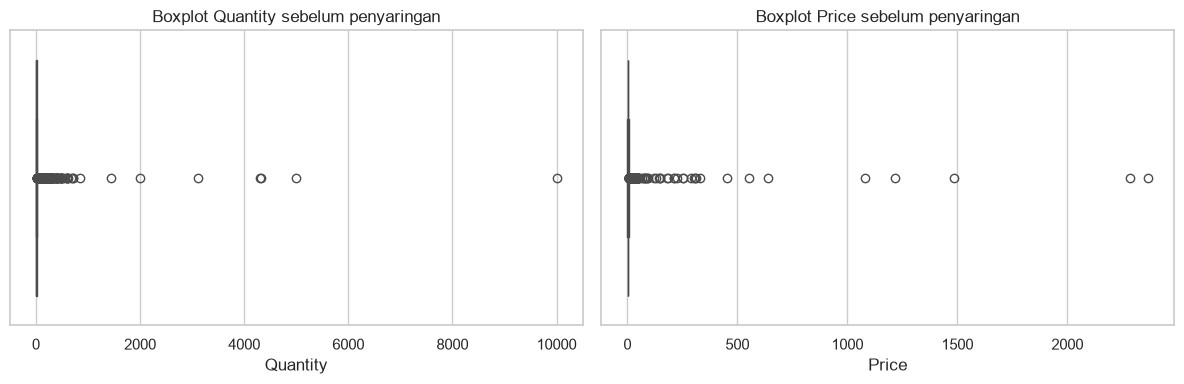

In [9]:
numeric_for_outlier = ["Quantity", "Price"]
plot_sample = df_clean[numeric_for_outlier].sample(
    n=min(20000, len(df_clean)), random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, numeric_for_outlier):
    sns.boxplot(x=plot_sample[col], ax=ax)
    ax.set_title(f"Boxplot {col} sebelum penyaringan")
plt.tight_layout()
plt.show()

In [10]:
df_before_outlier = df_clean.copy()

# Batas IQR dihitung pada kolom numerik yang dipakai
bounds = {}
for col in numeric_for_outlier:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    bounds[col] = (lower, upper)
    print(f"{col}: batas bawah={lower:.3f}, batas atas={upper:.3f}")

mask = pd.Series(True, index=df_clean.index)
for col, (lower, upper) in bounds.items():
    mask &= df_clean[col].between(lower, upper)

df_clean = df_clean.loc[mask].copy()
print("Baris sebelum penyaringan outlier:", len(df_before_outlier))
print("Baris setelah penyaringan outlier:", len(df_clean))
print("Baris yang tersaring:", len(df_before_outlier) - len(df_clean))

Quantity: batas bawah=-15.500, batas atas=28.500
Price: batas bawah=-3.100, batas atas=8.500
Baris sebelum penyaringan outlier: 1029610
Baris setelah penyaringan outlier: 911471
Baris yang tersaring: 118139


## 6. Menghapus Duplikasi dan Membuat Fitur Waktu
Memastikan duplikasi sudah tidak ada dan mengambil informasi jam, bulan, hari, serta hari dalam minggu dari InvoiceDate.

In [11]:
df_clean = df_clean.drop_duplicates().copy()
df_clean["InvoiceHour"] = df_clean["InvoiceDate"].dt.hour
df_clean["InvoiceMonth"] = df_clean["InvoiceDate"].dt.month
df_clean["InvoiceDay"] = df_clean["InvoiceDate"].dt.day
df_clean["InvoiceDayOfWeek"] = df_clean["InvoiceDate"].dt.dayofweek

print("Jumlah duplikat tersisa:", df_clean.duplicated().sum())
print("Ukuran data bersih:", df_clean.shape)
display(df_clean[["InvoiceDate", "InvoiceHour", "InvoiceMonth",
                  "InvoiceDay", "InvoiceDayOfWeek"]].head())

Jumlah duplikat tersisa: 0
Ukuran data bersih: (911471, 13)


,InvoiceDate,InvoiceHour,InvoiceMonth,InvoiceDay,InvoiceDayOfWeek
0,2009-12-01 07:45:00,7,12,1,1
1,2009-12-01 07:45:00,7,12,1,1
2,2009-12-01 07:45:00,7,12,1,1
4,2009-12-01 07:45:00,7,12,1,1
5,2009-12-01 07:45:00,7,12,1,1


## 7. Exploratory Data Analysis (EDA)
EDA membantu memahami distribusi transaksi dan negara dengan transaksi terbanyak. Grafik merupakan gambaran data setelah cleaning, bukan bukti hubungan sebab-akibat.

Statistik deskriptif setelah cleaning:


,count,mean,std,min,25%,50%,75%,max
Quantity,911471.0,6.122517,6.367584,1.000,1.00,3.00,10.00,28.0
Price,911471.0,2.718448,2.034279,0.001,1.25,2.08,3.75,8.5


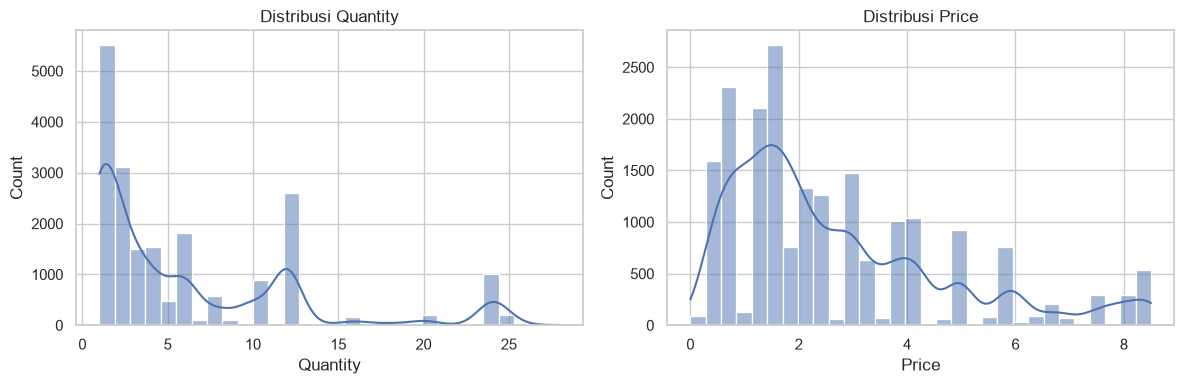

In [12]:
print("Statistik deskriptif setelah cleaning:")
display(df_clean[["Quantity", "Price"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["Quantity"].sample(n=min(20000, len(df_clean)), random_state=42),
             bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Quantity")
sns.histplot(df_clean["Price"].sample(n=min(20000, len(df_clean)), random_state=42),
             bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribusi Price")
plt.tight_layout()
plt.show()

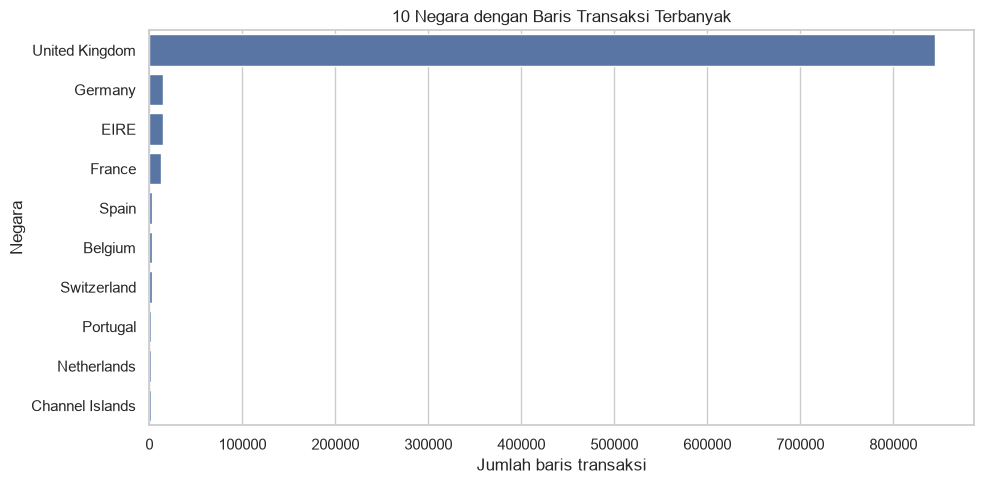

In [13]:
top_countries = df_clean["Country"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("10 Negara dengan Baris Transaksi Terbanyak")
plt.xlabel("Jumlah baris transaksi")
plt.ylabel("Negara")
plt.tight_layout()
plt.show()

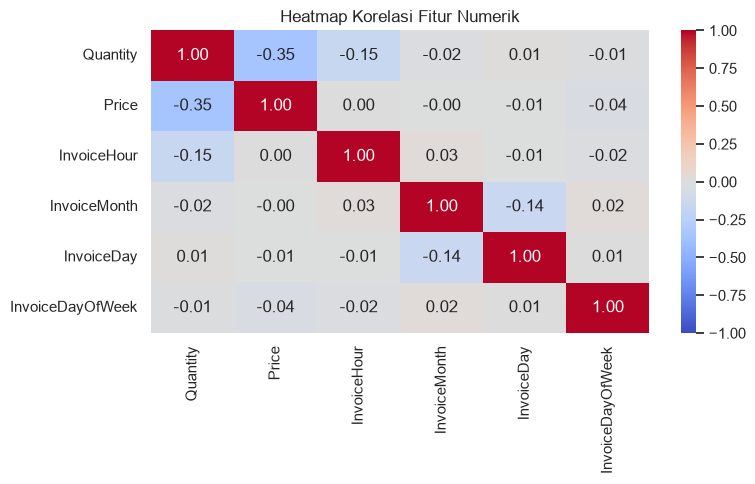

In [14]:
# Korelasi hanya untuk kolom numerik
corr_cols = ["Quantity", "Price", "InvoiceHour", "InvoiceMonth",
             "InvoiceDay", "InvoiceDayOfWeek"]
plt.figure(figsize=(8, 5))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Heatmap Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

## 8. Menyiapkan Dataset untuk Machine Learning
Target yang diprediksi adalah `Quantity` (jumlah barang pada baris transaksi). Fitur yang digunakan: Price, jam/bulan/hari transaksi, hari dalam minggu, dan Country. Kolom Invoice, StockCode, Description, Customer ID, dan Quantity tidak dimasukkan sebagai fitur agar tidak memakai identitas transaksi atau target itu sendiri.

In [15]:
feature_cols = ["Price", "InvoiceHour", "InvoiceMonth",
                "InvoiceDay", "InvoiceDayOfWeek", "Country"]
target_col = "Quantity"

model_data = df_clean[feature_cols + [target_col]].copy()
model_data = model_data.replace([np.inf, -np.inf], np.nan)
model_data = model_data.dropna(subset=[target_col])

# Sampel maksimum 50.000 baris untuk menjaga waktu komputasi JupyterLab
if len(model_data) > 50000:
    model_data = model_data.sample(n=50000, random_state=42)

X = model_data[feature_cols]
y = model_data[target_col]

print("Jumlah data untuk pemodelan:", len(model_data))
print("Jumlah fitur:", X.shape[1])
print("Target:", target_col)
display(model_data.head())

Jumlah data untuk pemodelan: 50000
Jumlah fitur: 6
Target: Quantity


,Price,InvoiceHour,InvoiceMonth,InvoiceDay,InvoiceDayOfWeek,Country,Quantity
23856,0.85,15,12,10,3,United Kingdom,10
472433,2.95,12,11,19,4,United Kingdom,2
305985,5.95,13,8,15,6,United Kingdom,3
532494,2.10,14,12,3,4,United Kingdom,1
406625,0.55,13,10,21,3,United Kingdom,3


## 9. Data Splitting
Data dibagi menjadi 80% training dan 20% testing. Data training digunakan untuk mempelajari pola, sedangkan data testing digunakan untuk mengukur kemampuan prediksi pada data yang tidak dipakai saat pelatihan.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (40000, 6)
X_test : (10000, 6)
y_train: (40000,)
y_test : (10000,)


## 10. Preprocessing dan Model Training
Kolom numerik diisi dengan median dan distandardisasi. Kolom Country diisi dengan modus lalu diubah menggunakan One-Hot Encoding. Pipeline menggabungkan preprocessing dengan Decision Tree Regressor.

In [17]:
numeric_features = ["Price", "InvoiceHour", "InvoiceMonth",
                     "InvoiceDay", "InvoiceDayOfWeek"]
categorical_features = ["Country"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", DecisionTreeRegressor(max_depth=12, random_state=42))
])

model.fit(X_train, y_train)
print("Model Decision Tree Regressor berhasil dilatih.")

Model Decision Tree Regressor berhasil dilatih.


## 11. Model Evaluation
Evaluasi regresi menggunakan MAE, MSE, RMSE, dan R². MAE/RMSE yang lebih rendah umumnya menunjukkan kesalahan prediksi yang lebih kecil. R² mendekati 1 menunjukkan model menjelaskan variasi target lebih baik; R² bukan akurasi klasifikasi.

In [18]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

comparison = pd.DataFrame({
    "Quantity Aktual": y_test.iloc[:10].values,
    "Quantity Prediksi": y_pred[:10]
})
display(comparison)

MAE  : 3.8036
MSE  : 30.2215
RMSE : 5.4974
R²   : 0.2414


,Quantity Aktual,Quantity Prediksi
0,4,22.500000
1,12,9.632143
2,3,6.760776
3,2,5.258964
4,2,2.242739
5,3,3.261404
6,1,8.182075
7,24,12.558824
8,6,4.050228
9,4,3.717949


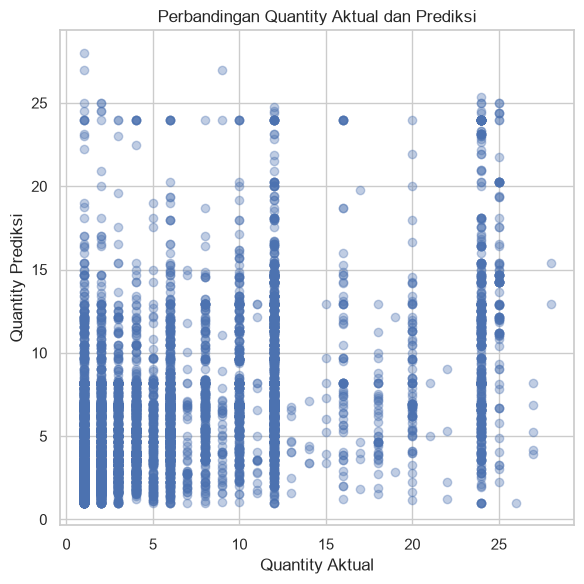

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.xlabel("Quantity Aktual")
plt.ylabel("Quantity Prediksi")
plt.title("Perbandingan Quantity Aktual dan Prediksi")
plt.tight_layout()
plt.show()

## 12. Cross Validation
Cross-validation 5-fold menguji model pada lima pembagian data. Proses ini membantu melihat apakah performa model relatif konsisten. Agar tidak terlalu berat, evaluasi dilakukan pada maksimal 10.000 baris dari data pemodelan.

In [20]:
cv_data = model_data.sample(n=min(10000, len(model_data)), random_state=42)
X_cv = cv_data[feature_cols]
y_cv = cv_data[target_col]

cv_scores = cross_val_score(
    model, X_cv, y_cv, cv=5, scoring="r2", n_jobs=-1
)

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: R² = {score:.4f}")
print(f"Rata-rata R²: {cv_scores.mean():.4f}")
print(f"Standar deviasi: {cv_scores.std():.4f}")

Fold 1: R² = -0.0011
Fold 2: R² = 0.0338
Fold 3: R² = 0.0729
Fold 4: R² = -0.0149
Fold 5: R² = -0.0525
Rata-rata R²: 0.0076
Standar deviasi: 0.0428


## 13. Kesimpulan Praktikum
Jalankan cell di bawah untuk membuat ringkasan otomatis berdasarkan hasil yang benar-benar diperoleh dari notebook. Nilai evaluasi bisa berbeda jika file, jumlah data, atau pengaturan model berbeda.

In [21]:
print("KESIMPULAN")
print(f"Dataset setelah pembersihan memiliki {len(df_clean):,} baris.")
print(f"Pemodelan menggunakan {len(model_data):,} baris dengan target Quantity.")
print(f"Nilai MAE = {mae:.4f}, artinya rata-rata selisih absolut prediksi Quantity sekitar {mae:.2f}.")
print(f"Nilai RMSE = {rmse:.4f}.")
print(f"Nilai R² pada data testing = {r2:.4f}.")
print(f"Rata-rata R² cross-validation = {cv_scores.mean():.4f}.")
print("Hasil ini merupakan evaluasi awal. Kualitas model perlu dinilai sesuai konteks bisnis,")
print("dan dapat ditingkatkan dengan pengujian fitur, parameter, serta model alternatif.")

KESIMPULAN
Dataset setelah pembersihan memiliki 911,471 baris.
Pemodelan menggunakan 50,000 baris dengan target Quantity.
Nilai MAE = 3.8036, artinya rata-rata selisih absolut prediksi Quantity sekitar 3.80.
Nilai RMSE = 5.4974.
Nilai R² pada data testing = 0.2414.
Rata-rata R² cross-validation = 0.0076.
Hasil ini merupakan evaluasi awal. Kualitas model perlu dinilai sesuai konteks bisnis,
dan dapat ditingkatkan dengan pengujian fitur, parameter, serta model alternatif.
